In [113]:
import pandas as pd
from sklearn import metrics
from sklearn.model_selection import train_test_split
from sklearn.metrics import recall_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.tree import DecisionTreeClassifier
from imblearn.combine import SMOTEENN

In [115]:
df=pd.read_csv("tel_churn (1).csv")
df.head()

,Unnamed: 0,SeniorCitizen,MonthlyCharges,TotalCharges,Churn,gender_Female,gender_Male,Partner_No,Partner_Yes,Dependents_No,...,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,tenure_group_1 - 12,tenure_group_13 - 24,tenure_group_25 - 36,tenure_group_37 - 48,tenure_group_49 - 60,tenure_group_61 - 72
0,0,0,29.85,29.85,0,1,0,0,1,1,...,0,0,1,0,1,0,0,0,0,0
1,1,0,56.95,1889.50,0,0,1,1,0,1,...,0,0,0,1,0,0,1,0,0,0
2,2,0,53.85,108.15,1,0,1,1,0,1,...,0,0,0,1,1,0,0,0,0,0
3,3,0,42.30,1840.75,0,0,1,1,0,1,...,1,0,0,0,0,0,0,1,0,0
4,4,0,70.70,151.65,1,1,0,1,0,1,...,0,0,1,0,1,0,0,0,0,0


In [117]:
valid_columns = [
    'Contract_Month-to-month',
    'TotalCharges',
    'InternetService_Fiber optic',
    'MonthlyCharges',
    'PaymentMethod_Electronic check',
    'MultipleLines_No',
    'OnlineBackup_No'
]

In [119]:
df=df.drop('Unnamed: 0',axis=1)

In [121]:
# Ensure 'Churn' is dropped and only valid features are kept
x = df[valid_columns].copy()
y = df['Churn']  # If target variable is 'Churn'
x

,Contract_Month-to-month,TotalCharges,InternetService_Fiber optic,MonthlyCharges,PaymentMethod_Electronic check,MultipleLines_No,OnlineBackup_No
0,1,29.85,0,29.85,1,0,0
1,0,1889.50,0,56.95,0,1,1
2,1,108.15,0,53.85,0,1,0
3,0,1840.75,0,42.30,0,0,1
4,1,151.65,1,70.70,1,1,1
...,...,...,...,...,...,...,...
7027,0,1990.50,0,84.80,0,0,1
7028,0,7362.90,1,103.20,0,0,0
7029,1,346.45,0,29.60,1,0,1
7030,1,306.60,1,74.40,0,0,1


In [123]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2)

In [125]:
model_dt=DecisionTreeClassifier(criterion = "gini",random_state = 100,max_depth=6, min_samples_leaf=8)

In [127]:

model_dt.fit(x_train,y_train)

DecisionTreeClassifier(max_depth=6, min_samples_leaf=8, random_state=100)

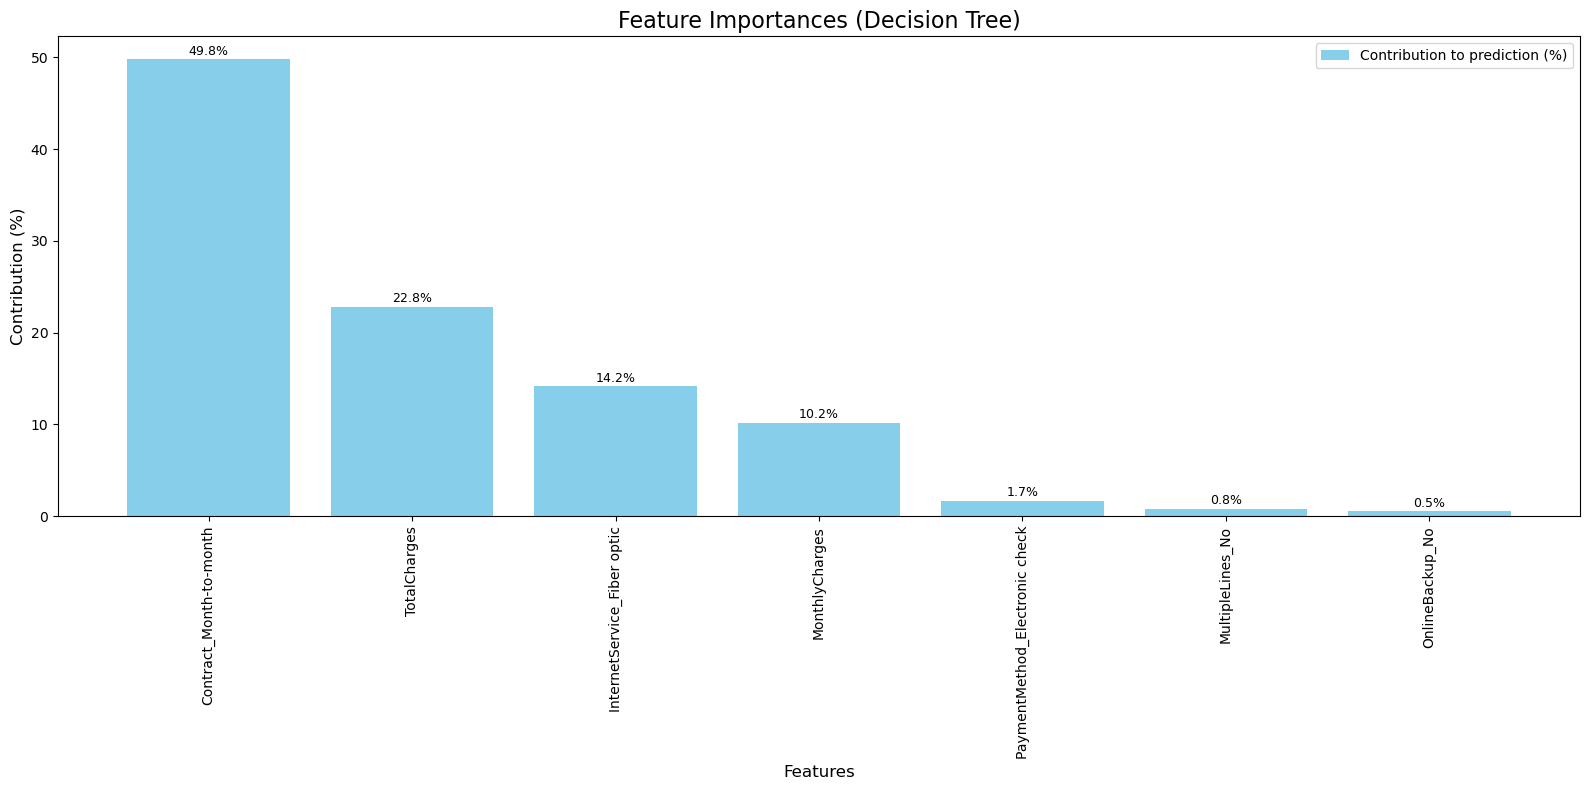

In [129]:
import numpy as np
import matplotlib.pyplot as plt

# Feature importance extraction
importances = model_dt.feature_importances_
features = x.columns
indices = np.argsort(importances)[::-1]

# Convert importances to percentages
importances_percent = 100.0 * (importances / importances.sum())

# Plot
plt.figure(figsize=(16, 8))
bars = plt.bar(range(len(importances)), importances_percent[indices], color='skyblue', align='center')

# Axis labels
plt.title("Feature Importances (Decision Tree)", fontsize=16)
plt.xlabel("Features", fontsize=12)
plt.ylabel("Contribution (%)", fontsize=12)
plt.xticks(range(len(importances)), [features[i] for i in indices], rotation=90)

# Add value labels on top of bars
for bar, imp in zip(bars, importances_percent[indices]):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 0.5, f'{imp:.1f}%', ha='center', fontsize=9)

# Add legend
plt.legend(["Contribution to prediction (%)"], loc='upper right')

plt.tight_layout()
plt.show()


In [131]:
y_pred=model_dt.predict(x_test)

In [133]:
model_dt.score(x_test,y_test)

0.7803837953091685

In [135]:
print(classification_report(y_test, y_pred, labels=[0,1]))

              precision    recall  f1-score   support

           0       0.83      0.88      0.85      1024
           1       0.62      0.51      0.56       383

    accuracy                           0.78      1407
   macro avg       0.72      0.70      0.71      1407
weighted avg       0.77      0.78      0.77      1407



In [137]:
from imblearn.combine import SMOTEENN

sm = SMOTEENN()
X_resampled, y_resampled = sm.fit_resample(x, y)


In [139]:
xr_train,xr_test,yr_train,yr_test=train_test_split(X_resampled, y_resampled,test_size=0.2)

In [141]:
model_dt_smote=DecisionTreeClassifier(criterion = "gini",random_state = 100,max_depth=6, min_samples_leaf=8)

In [143]:
model_dt_smote.fit(xr_train,yr_train)
yr_predict = model_dt_smote.predict(xr_test)
model_score_r = model_dt_smote.score(xr_test, yr_test)
print(model_score_r)
print(metrics.classification_report(yr_test, yr_predict))

0.9100719424460432
              precision    recall  f1-score   support

           0       0.91      0.91      0.91       538
           1       0.91      0.91      0.91       574

    accuracy                           0.91      1112
   macro avg       0.91      0.91      0.91      1112
weighted avg       0.91      0.91      0.91      1112



In [145]:
print(metrics.confusion_matrix(yr_test, yr_predict))

[[489  49]
 [ 51 523]]


In [149]:
# ✔️ Correct way to save
import pickle

# Train your model
from sklearn.tree import DecisionTreeClassifier
model = DecisionTreeClassifier()
model.fit(x_train, y_train)

# Save the actual model object
with open('model.pkl', 'wb') as f:
    pickle.dump(model, f)
